In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
rows = 4
cols = 4

start = 0
goal = 15

actions = ["Up", "Down", "Left", "Right"]

def move(state, action):
    row = state // cols
    col = state % cols

    if action == 0:       # Up
        row = max(0, row - 1)
    elif action == 1:     # Down
        row = min(rows - 1, row + 1)
    elif action == 2:     # Left
        col = max(0, col - 1)
    elif action == 3:     # Right
        col = min(cols - 1, col + 1)

    new_state = row * cols + col

    if new_state == goal:
        reward = 10
    else:
        reward = -1

    return new_state, reward

In [3]:
Q = np.zeros((16, 4))

alpha = 0.1
gamma = 0.9
epsilon = 0.1

episodes = 1000

In [4]:
rewards = []
success = []

for episode in range(episodes):

    state = start
    total_reward = 0

    for step in range(50):

        # Epsilon-greedy strategy
        if np.random.random() < epsilon:
            action = np.random.randint(4)
        else:
            action = np.argmax(Q[state])

        new_state, reward = move(state, action)

        # Q-learning update
        Q[state, action] = Q[state, action] + alpha * (
            reward + gamma * np.max(Q[new_state])
            - Q[state, action]
        )

        state = new_state
        total_reward += reward

        if state == goal:
            break

    rewards.append(total_reward)
    success.append(1 if state == goal else 0)

print("Training Completed!")

Training Completed!


In [5]:
print("Average Cumulative Reward:",
      np.mean(rewards))

print("Success Rate:",
      np.mean(success) * 100, "%")

Average Cumulative Reward: 4.13
Success Rate: 99.9 %


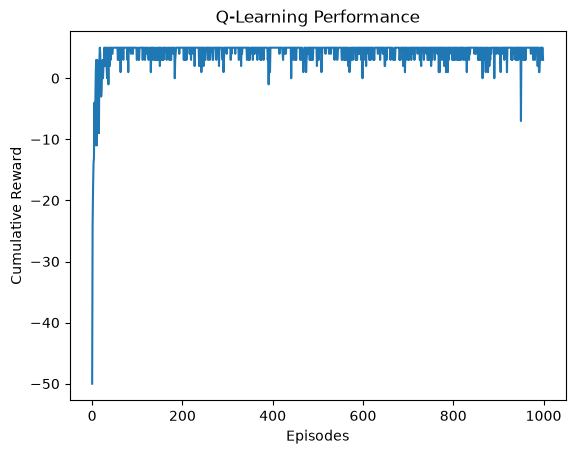

In [6]:
plt.plot(rewards)
plt.xlabel("Episodes")
plt.ylabel("Cumulative Reward")
plt.title("Q-Learning Performance")
plt.show()

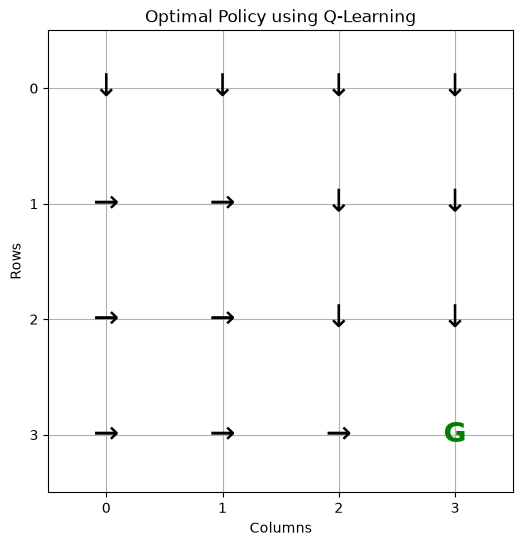

In [9]:
plt.figure(figsize=(6, 6))

symbols = ["↑", "↓", "←", "→"]

for i in range(16):
    row = i // 4
    col = i % 4

    if i == goal:
        plt.text(col, row, "G", ha="center",
                 va="center", fontsize=20, color="green",
                 fontweight="bold")
    else:
        best_action = np.argmax(Q[i])

        plt.text(col, row, symbols[best_action],
                 ha="center", va="center", fontsize=22)

plt.xticks(range(4))
plt.yticks(range(4))
plt.xlim(-0.5, 3.5)
plt.ylim(3.5, -0.5)

plt.grid(True)
plt.title("Optimal Policy using Q-Learning")
plt.xlabel("Columns")
plt.ylabel("Rows")
plt.show()

In [10]:
def train_agent(epsilon):

    Q = np.zeros((16, 4))
    rewards = []
    success = []

    for episode in range(1000):

        state = start
        total = 0

        for step in range(50):

            if np.random.random() < epsilon:
                action = np.random.randint(4)
            else:
                action = np.argmax(Q[state])

            new_state, reward = move(state, action)

            Q[state, action] += alpha * (
                reward + gamma * np.max(Q[new_state])
                - Q[state, action]
            )

            state = new_state
            total += reward

            if state == goal:
                break

        rewards.append(total)
        success.append(state == goal)

    return np.mean(rewards), np.mean(success) * 100


for e in [0.1, 0.3, 0.5]:
    r, s = train_agent(e)
    print("Epsilon:", e,
          "Average Reward:", round(r, 2),
          "Success Rate:", round(s, 2), "%")

Epsilon: 0.1 Average Reward: 4.07 Success Rate: 99.8 %
Epsilon: 0.3 Average Reward: 2.43 Success Rate: 99.8 %
Epsilon: 0.5 Average Reward: -0.2 Success Rate: 99.9 %
